In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [25]:
stroke_data = pd.read_csv("stroke-prediction.csv")
X = stroke_data.drop(columns = ["stroke", "id"])
y = stroke_data["stroke"]
names = stroke_data.columns
print(names)

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


Covariance matrix:
  [[1.   0.24]
 [0.24 1.  ]]


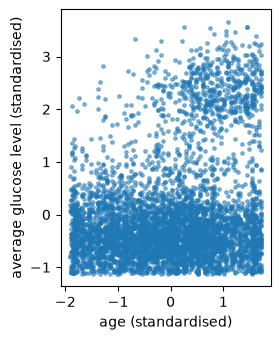

In [34]:
features = ["age", "avg_glucose_level"]

X2 = StandardScaler().fit_transform(X[features])
Sigma = np.cov(X2, rowvar = False)

print("Covariance matrix:\n ", Sigma.round(2))

fig, ax = plt.subplots(figsize = (4, 3.6))
ax.scatter(X2[:, 0], X2[:, 1], s = 6, alpha = 0.5)
ax.set_xlabel("age (standardised)")
ax.set_ylabel("average glucose level (standardised)")
_ = ax.set_aspect("equal")

Principle axes 1: 0.79
Principal axes 2: 2.35
Therefore, total variance is: 3.14


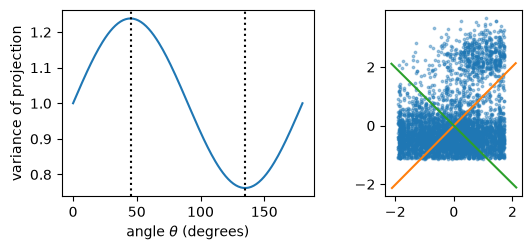

In [42]:
thetas = np.linspace(0, np.pi, 180)
var_z = [np.var(X2 @ np.array([np.cos(t), np.sin(t)]), ddof = 1) for t in thetas]
best = thetas[np.argmax(var_z)]
worst = thetas[np.argmin(var_z)]

print(f"Principle axes 1: {best:.2f}")
print(f"Principal axes 2: {worst:.2f}")
print(f"Therefore, total variance is: {best + worst:.2f}")

fig, axs = plt.subplots(1, 2, figsize = (6, 2.6))
axs[0].plot(np.degrees(thetas), var_z)
axs[0].axvline(np.degrees(best), color = "k", linestyle = ":")
axs[0].axvline(np.degrees(worst), color = "k", linestyle = ":")
axs[0].set_xlabel(r"angle $\theta$ (degrees)")
axs[0].set_ylabel("variance of projection")
axs[1].scatter(X2[:, 0], X2[:, 1], s = 3, alpha = 0.4)
for t, c in [(best, "C1"), (best + np.pi / 2, "C2")]:
    axs[1].plot([-3 * np.cos(t), 3 * np.cos(t)], [-3 * np.sin(t), 3 * np.sin(t)], c)
axs[1].set_aspect("equal")
plt.tight_layout()

In [43]:
evals, evecs = np.linalg.eigh(Sigma)
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]
print("eigenvalues", evals.round(2), " sum:", evals.sum().round(2))
print("eigenvectors (columns):\n", evecs.round(3))
Z2 = X2 @ evecs
print("covariance of the scores:\n", np.cov(Z2, rowvar = False).round(2))

eigenvalues [1.24 0.76]  sum: 2.0
eigenvectors (columns):
 [[ 0.707 -0.707]
 [ 0.707  0.707]]
covariance of the scores:
 [[1.24 0.  ]
 [0.   0.76]]


In [44]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

In [50]:
# Convert categorical columns to numeric dummy variables
Xw = pd.get_dummies(X, drop_first=False, dtype=float)

# Convert any missing values, such as N/A in bmi, to the column median
Xw = Xw.apply(pd.to_numeric, errors="coerce")
Xw = Xw.fillna(Xw.median())

feature_names = Xw.columns.to_numpy()

raw = PCA().fit(Xw)
std = make_pipeline(StandardScaler(), PCA()).fit(Xw)

print("explained variance ratio, raw:",
      raw.explained_variance_ratio_[:4].round(3))
print("explained variance ratio, scaled:",
      std[-1].explained_variance_ratio_[:4].round(3))

j = np.argmax(np.abs(raw.components_[0]))

print(f"raw PC1 is dominated by '{feature_names[j]}'"
      f"(variance {Xw.iloc[:, j].var():.0f}; "
      f"next largest {np.sort(Xw.var(axis=0))[-2]:.0f})")

explained variance ratio, raw: [0.797 0.183 0.02  0.   ]
explained variance ratio, scaled: [0.192 0.099 0.096 0.081]
raw PC1 is dominated by 'avg_glucose_level'(variance 2051; next largest 511)


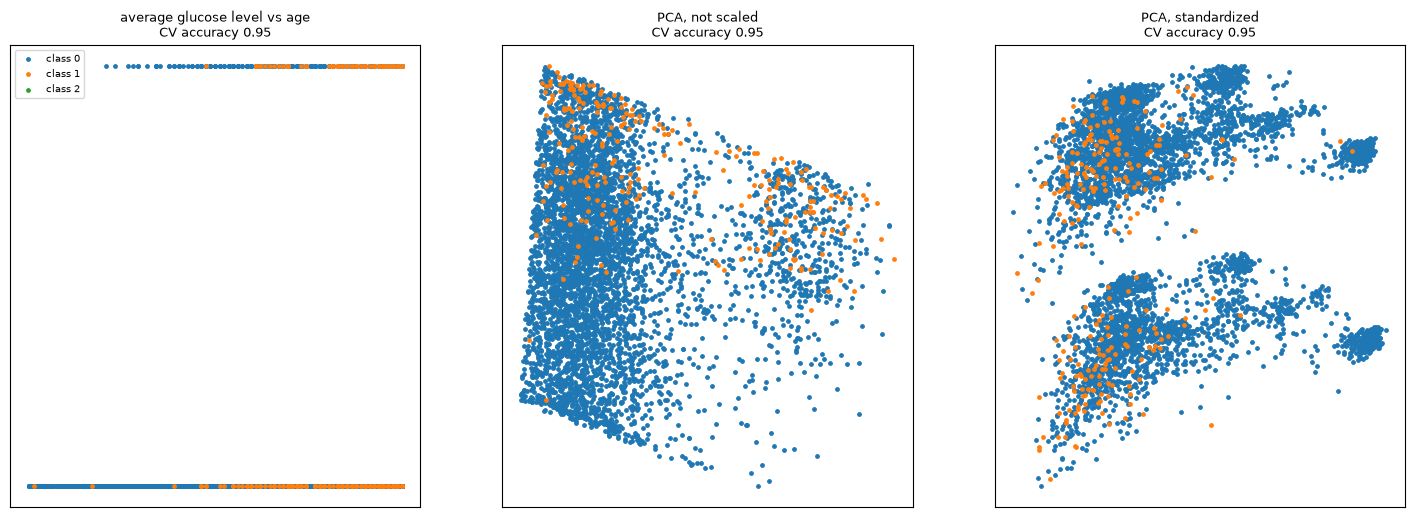

In [56]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(5, shuffle=True, random_state = 0)

Zw = std.transform(Xw)

views = [("average glucose level vs age", Xw.iloc[:, :2].to_numpy()), 
        ("PCA, not scaled", raw.transform(Xw)[:, :2]), 
        ("PCA, standardized", Zw[:, :2])]

fig, axs = plt.subplots(1, 3, figsize = (18, 6))
for ax, (title, P2) in zip(axs, views):
    acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), P2, y, cv = cv).mean()
    for c in range(3):
        ax.scatter(P2[y == c, 0], P2[y == c, 1], s = 6, label = f"class {c}")
    ax.set_title(f"{title}\nCV accuracy {acc:.2f}", fontsize = 9)
    ax.set_xticks([]); ax.set_yticks([])
_ = axs[0].legend(fontsize = 7)